In [1]:
import torch 
from torch import nn, Tensor

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [ ]:
import torch
import torch.nn as nn
from torch import Tensor

class Flow(nn.Module):
    def __init__(self, dim: int = 2, h: int = 64):
        """
        Initializes the Flow neural network.

        Args:
            dim (int): Dimensionality of the input data (default: 2).
            h (int): Number of hidden units in the neural network (default: 64).
        """
        super().__init__()
        # Define the neural network architecture using a sequential container.
        # The network consists of alternating Linear and ELU layers.
        self.net = nn.Sequential(
            nn.Linear(dim + 1, h),  # First linear layer: input size (dim + 1), output size h.
            nn.ELU(),               # Exponential Linear Unit (ELU) activation function.
            nn.Linear(h, h),        # Second linear layer: input size h, output size h.
            nn.ELU(),               # ELU activation function.
            nn.Linear(h, h),       # Third linear layer: input size h, output size h.
            nn.ELU(),              # ELU activation function.
            nn.Linear(h, dim)       # Final linear layer: input size h, output size dim.
        )
    
    def forward(self, t: Tensor, x_t: Tensor) -> Tensor:
        """
        Defines the forward pass of the neural network.

        Args:
            t (Tensor): A tensor representing time (or an additional feature).
            x_t (Tensor): A tensor representing the input data at time t.

        Returns:
            Tensor: The output of the neural network after processing the concatenated input.
        """
        # Concatenate the time tensor `t` and the input tensor `x_t` along the last dimension.
        # This results in a tensor of size (batch_size, dim + 1).
        combined_input = torch.cat((t, x_t), -1)
        
        # Pass the concatenated input through the neural network.
        return self.net(combined_input)
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        """
        Performs a step operation, likely related to integrating or stepping forward in time.

        Args:
            x_t (Tensor): The input data at time `t_start`.
            t_start (Tensor): The starting time.
            t_end (Tensor): The ending time.

        Returns:
            Tensor: The updated state after performing the step operation.
        """
        # Reshape `t_start` to match the batch size of `x_t`.
        # `view(1, 1)` reshapes `t_start` to a 1x1 tensor, and `expand` replicates it to match the batch size.
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        
        # Compute the midpoint time between `t_start` and `t_end`.
        midpoint_time = t_start + (t_end - t_start) / 2
        
        # Compute an intermediate value by evaluating the network at `t_start`.
        intermediate_value = self(x_t=x_t, t=t_start)
        
        # Update `x_t` by adding a scaled version of the intermediate value.
        updated_x_t = x_t + intermediate_value * (t_end - t_start) / 2
        
        # Evaluate the network at the midpoint time and updated state.
        midpoint_output = self(t=midpoint_time, x_t=updated_x_t)
        
        # Compute the final output by adding a scaled version of the midpoint output to `x_t`.
        return x_t + (t_end - t_start) * midpoint_output

# Training

In [46]:
flow = Flow()

optimizer = torch.optim.Adam(flow.parameters(), 1e-2)
loss_fn = nn.MSELoss()

for _ in range(10000):
    x_1 = Tensor(make_moons(256, noise=0.05)[0])
    x_0 = torch.randn_like(x_1)
    t = torch.rand(len(x_1), 1)

    x_t = (1 - t) * x_0 + t * x_1
    dx_t = x_1 - x_0
    
    optimizer.zero_grad()
    loss_fn(flow(t=t, x_t=x_t), dx_t).backward()
    optimizer.step()

# Sampling

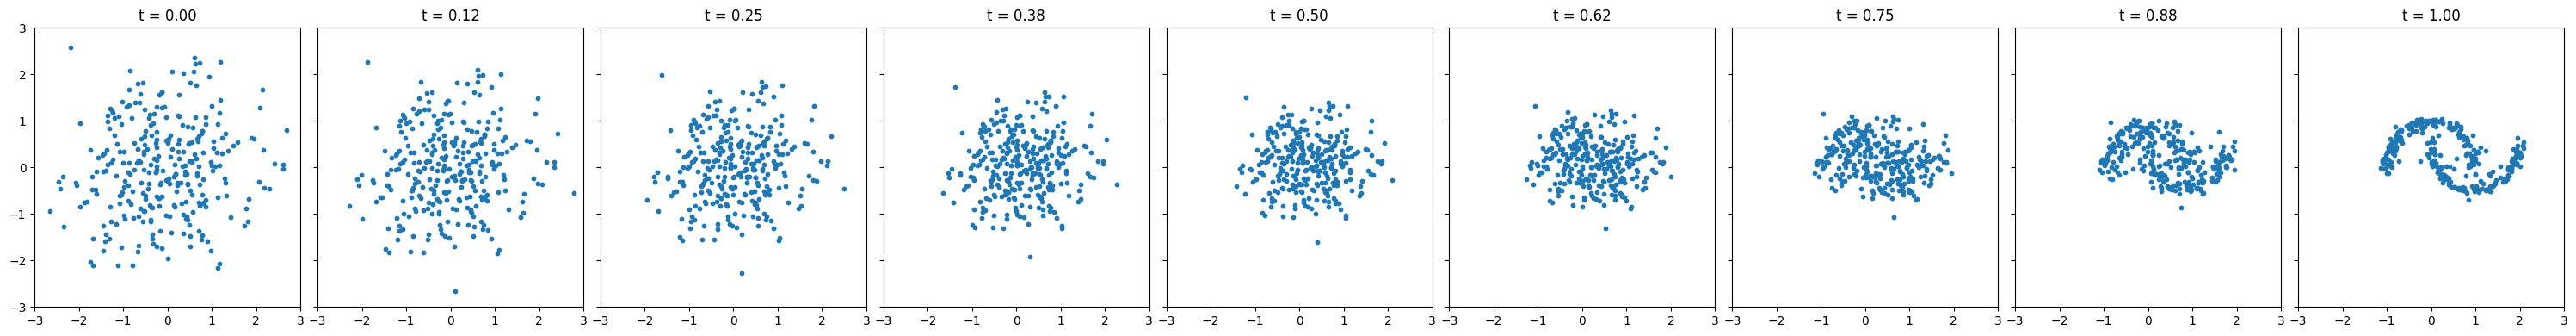

In [4]:
x = torch.randn(300, 2)
n_steps = 8
fig, axes = plt.subplots(1, n_steps + 1, figsize=(30, 4), sharex=True, sharey=True)
time_steps = torch.linspace(0, 1.0, n_steps + 1)

axes[0].scatter(x.detach()[:, 0], x.detach()[:, 1], s=10)
axes[0].set_title(f't = {time_steps[0]:.2f}')
axes[0].set_xlim(-3.0, 3.0)
axes[0].set_ylim(-3.0, 3.0)

for i in range(n_steps):
    x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    axes[i + 1].scatter(x.detach()[:, 0], x.detach()[:, 1], s=10)
    axes[i + 1].set_title(f't = {time_steps[i + 1]:.2f}')

plt.tight_layout()
plt.show()

In [42]:
class Car: 
    def __init__(self, make: str, model: str, year: int, mileage: int): # use the __init__ to define attributes of the class 
        self.make = make # define make of vehicle as an attribute
        self.model = model 
        self.year = year 
        self.mileage = mileage

    def drive(self, miles): # define method for updating vehicle mileage and argument to pass to the class 
        self.mileage += miles

    def display_info(self): # define method to print out vehicle information
        print(f'You car is a {self.year} {self.make} {self.model} with {self.mileage} miles')


In [ ]:
my_car = Car(make="Volkswagen", model="Taos", year=2023, mileage=23000) # define an instance of a class 

my_car.drive(miles=200) # call on method for the instance 
x = my_car.display_info() # call on method for the instance 

You car is a 2023 Volkswagen Taos with 23200 miles
